Hello this is a jupyter notebook. In this next cell I will add 2 + 2

In [3]:
2+2

4

Practise variables and calculations test

In [4]:
irradiation = 950
area = 10

estimated_energy = irradiation * area
estimated_energy

9500

In [5]:
daily_irradiation = [1.8, 2.4, 3.1, 2.7, 3.5]

sum(daily_irradiation) / len(daily_irradiation)

2.7

In [6]:
from pathlib import Path

Path.cwd()

WindowsPath('c:/Users/EllaNorman/OneDrive - Bluefield Group/Documents/IrradiationMapProject/rawdata')

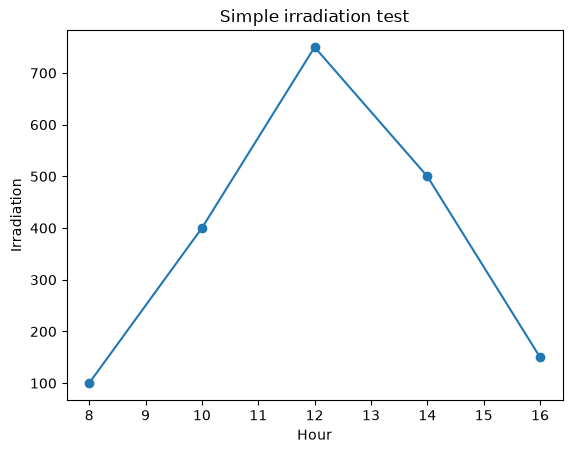

In [7]:
import matplotlib.pyplot as plt

hours = [8, 10, 12, 14, 16]
irradiation = [100, 400, 750, 500, 150]

plt.plot(hours, irradiation, marker="o")
plt.xlabel("Hour")
plt.ylabel("Irradiation")
plt.title("Simple irradiation test")
plt.show()

# UK solar irradiation map

This notebook creates a UK solar irradiation map from ERA5 surface solar radiation downwards data.

The process:

1. Load and inspect the ERA5 NetCDF file.
2. standardise its coordinates.
3. select the required time period.
4. crop the data to the UK.
5. convert SSRD from J/m² to kWh/m².
6. add the UK boundary.
7. display and save the finished map.

The current version uses the full ERA5 global dataset and then filters it down to the UK. An improvement will be added to download UK-only data directly

In [8]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import xarray as xr

In [22]:
ds = xr.open_dataset(INPUT_FILE)
ds

<xarray.Dataset> Size: 12kB
Dimensions:     (valid_time: 1, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2026-09-01T06:00:00
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 11kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-26T17:00 GRIB to CDM+CF via cfgrib-0.9.1...

In [23]:
# File settings
INPUT_FILE = Path("Novdata.nc")
OUTPUT_FILE = Path("uk_irradiation_map.png")

# ERA5 settings
VARIABLE = "ssrd"
TIME_INDEX = 0

# UK map limits
UK_BOUNDS = {
    "west": -8.6,
    "east": 2.0,
    "south": 49.0,
    "north": 61.0,
}

# UK boundary data
NATURAL_EARTH_URL = (
    "https://naturalearth.s3.amazonaws.com/10m_cultural/"
    "ne_10m_admin_0_countries.zip"
)

In [24]:
print(Path.cwd())
print(INPUT_FILE)
print(INPUT_FILE.exists())

c:\Users\EllaNorman\OneDrive - Bluefield Group\Documents\IrradiationMapProject\rawdata
Novdata.nc
True


## Load and inspect the data

Opening the NetCDF file and displaying its dimensions, coordinates, variables and metadata.

In [25]:
from pathlib import Path
#just checking the file name and location is correct
list(Path("rawdata").glob("*.nc"))

[]

In [26]:
ds = xr.open_dataset(INPUT_FILE)
ds

<xarray.Dataset> Size: 12kB
Dimensions:     (valid_time: 1, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2026-10-01T06:00:00
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 11kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-16T11:42 GRIB to CDM+CF via cfgrib-0.9.1...

## Prepare the coordinates

Standardise the latitude and longitude coordinates before selecting the UK region.

In [27]:
# Convert longitude to the -180 to 180 range and sort it
ds = ds.assign_coords(
    longitude=((ds.longitude + 180) % 360) - 180
).sortby("longitude")

# Ensure latitude runs from north to south
if float(ds.latitude[0]) < float(ds.latitude[-1]):
    ds = ds.sortby("latitude", ascending=False)

ds

<xarray.Dataset> Size: 12kB
Dimensions:     (valid_time: 1, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2026-10-01T06:00:00
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 11kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-16T11:42 GRIB to CDM+CF via cfgrib-0.9.1...

## Select the UK irradiation data

Select the September 2026 SSRD data and crop it to the UK map area

In [28]:
# Select September 2026
irradiation = ds[VARIABLE].isel(valid_time=TIME_INDEX)

# Crop the data to the UK region
irradiation_uk = irradiation.sel(
    latitude=slice(UK_BOUNDS["north"], UK_BOUNDS["south"]),
    longitude=slice(UK_BOUNDS["west"], UK_BOUNDS["east"]),
)

irradiation_uk

<xarray.DataArray 'ssrd' (latitude: 49, longitude: 43)> Size: 8kB
[2107 values with dtype=float32]
Coordinates:
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 344B -8.5 -8.25 -8.0 -7.75 ... 1.5 1.75 2.0
    number      int64 8B ...
    valid_time  datetime64[ns] 8B 2026-10-01T06:00:00
    expver      <U4 16B ...
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      2793
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Surface short-wave (solar) radi...
    units:                                    J m**-2
    standard_name:                            surface_downwelling_shortwave_f...
    GRIB_surface:                             0.0

## Convert the irradiation units

Convert surface solar radiation downwards from J/m² to kWh/m².

In [29]:
irradiation_kwh = irradiation_uk / 3_600_000

irradiation_kwh.attrs["units"] = "kWh/m²"

print(f"Minimum: {float(irradiation_kwh.min()):.2f} kWh/m²")
print(f"Maximum: {float(irradiation_kwh.max()):.2f} kWh/m²")
print(f"Mean: {float(irradiation_kwh.mean()):.2f} kWh/m²")

Minimum: 1.07 kWh/m²
Maximum: 2.46 kWh/m²
Mean: 1.63 kWh/m²


## Load the UK boundary

Load the United Kingdom country boundary from Natural Earth (a downloaded package)

In [30]:
world = gpd.read_file(NATURAL_EARTH_URL)

uk_boundary = world.loc[
    world["ADMIN"] == "United Kingdom"
].copy()

if uk_boundary.crs is not None and uk_boundary.crs.to_epsg() != 4326:
    uk_boundary = uk_boundary.to_crs(epsg=4326)

uk_boundary

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
78,Admin-0 country,0,2,United Kingdom,GB1,1,2,Country,1,United Kingdom,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-7.2471 55.06932, -7.25674 55...."


## Create the UK irradiation map

Plot the September 2026 irradiation data, overlay the UK boundary and save the finished map!

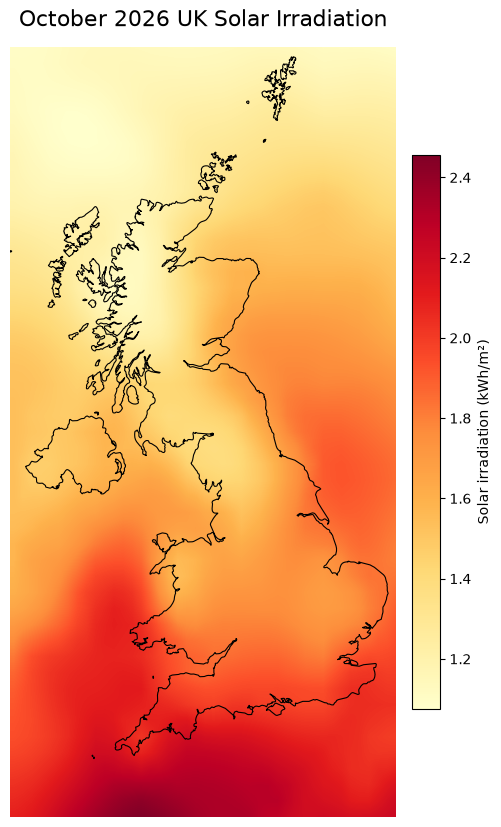

Map saved to: C:\Users\EllaNorman\uk_irradiation_map.png


In [31]:
fig, ax = plt.subplots(figsize=(8, 10))

image = irradiation_kwh.plot.imshow(
    ax=ax,
    cmap="YlOrRd",
    interpolation="bilinear",
    add_colorbar=False,
    x="longitude",
    y="latitude",
)

colourbar = fig.colorbar(
    image,
    ax=ax,
    shrink=0.72,
    pad=0.025,
)

colourbar.set_label("Solar irradiation (kWh/m²)")

uk_boundary.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8,
)

ax.set_xlim(UK_BOUNDS["west"], UK_BOUNDS["east"])
ax.set_ylim(UK_BOUNDS["south"], UK_BOUNDS["north"])

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "October 2026 UK Solar Irradiation",
    fontsize=16,
    pad=15,
)

OUTPUT_FILE = Path.home() / "uk_irradiation_map.png"

fig.savefig(
    str(OUTPUT_FILE),
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Map saved to: {OUTPUT_FILE}")